# 05 — фаза 5: самонавчальна доменна адаптація (EXPLORATORY)

Ноутбук лише читає збережені таблиці `reports/tables/phase5_*.csv`; нічого не перераховує. Гіпотезу сформульовано після
перегляду test. Енкодер, адаптований на фолді F, оцінюється лише на іншому фолді. Деталі: `reports/phase5_summary.md`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

from malaria_ssl.detr.compare import plot_paired_diffs
from malaria_ssl.utils.config import resolve_path

T = resolve_path('reports/tables')
F = resolve_path('reports/figures')


def ci(v, lo, hi):
    return f'{v:.3f} [{lo:.3f}, {hi:.3f}]'


def wide(df, index, columns, v='value', lo='ci_low', hi='ci_high'):
    """Long table of value + CI -> formatted pivot."""
    d = df.assign(s=[ci(a, b, c) for a, b, c in zip(df[v], df[lo], df[hi])])
    return d.pivot(index=index, columns=columns, values='s')


## AUPRC infected на тестових фолдах

Середнє двох фолдів, 95% ДІ, класифікатори навчені на train.

In [2]:
r = pd.concat([pd.read_csv(T / 'phase5_da_runs.csv'), pd.read_csv(T / 'phase5_dino_folds_runs.csv')])
r = r[r['eval'] == 'avg'].drop_duplicates(['encoder', 'metric'])
wide(r, 'encoder', 'metric')

metric,knn_auprc,linear_auprc
encoder,,
dino,"0.925 [0.891, 0.956]","0.910 [0.879, 0.943]"
imagenet,"0.754 [0.701, 0.813]","0.877 [0.838, 0.917]"
imagenet_cont,"0.816 [0.765, 0.871]","0.906 [0.875, 0.938]"
imagenet_da,"0.759 [0.701, 0.825]","0.748 [0.699, 0.802]"
joint,"0.764 [0.718, 0.816]","0.811 [0.770, 0.857]"
joint_cont,"0.753 [0.707, 0.807]","0.809 [0.762, 0.861]"
joint_da,"0.882 [0.849, 0.918]","0.854 [0.820, 0.889]"


## Стабільність за seed

Два seed одного рецепта `imagenet_da`.

In [3]:
s = pd.read_csv(T / 'phase5_da_seeds_runs.csv')
wide(s[s['eval'] == 'avg'], 'encoder', 'metric')

metric,knn_auprc,linear_auprc
encoder,,
imagenet,"0.754 [0.701, 0.813]","0.877 [0.838, 0.917]"
imagenet_cont,"0.816 [0.765, 0.871]","0.906 [0.875, 0.938]"
imagenet_da,"0.759 [0.701, 0.825]","0.748 [0.699, 0.802]"
imagenet_da_2seeds,"0.780 [0.726, 0.838]","0.821 [0.784, 0.862]"
imagenet_da_seed2,"0.801 [0.735, 0.869]","0.894 [0.859, 0.928]"


## Парні різниці (середнє фолдів)

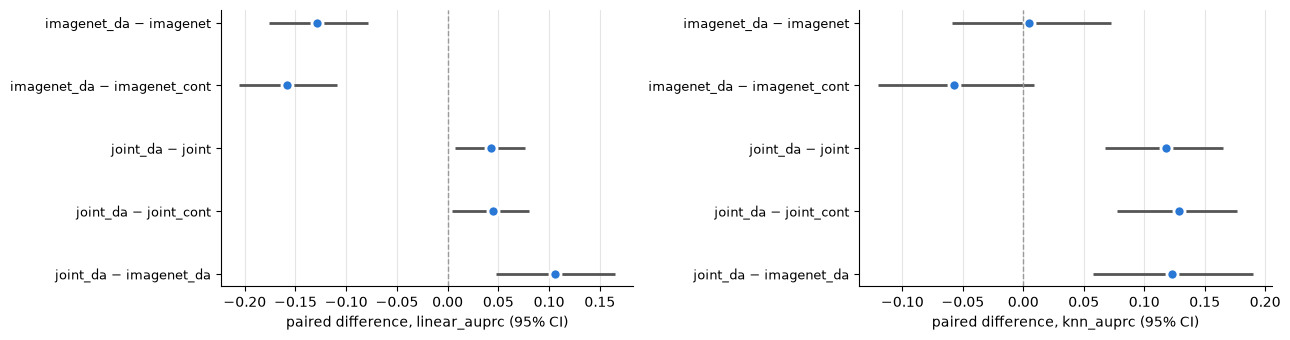

In [4]:
d = pd.read_csv(T / 'phase5_da_diff.csv').rename(columns={'ci_low': 'low', 'ci_high': 'high'})
d = d[d['eval'] == 'avg']
fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
plot_paired_diffs(d, 'linear_auprc', axes[0])
plot_paired_diffs(d, 'knn_auprc', axes[1])
plt.tight_layout()